# NF-UNSW-NB15 v3 Dataset Analysis

**Repository**: TRENCH-IDS Research  
**Dataset**: `data/UNSW/data/NF-UNSW-NB15-v3.csv`  
**Feature reference**: `v3/UNSW/data/NetFlow_v3_Features.csv`

## Who this notebook is for

Anyone who wants a complete, beginner-friendly picture of the NF-UNSW-NB15 v3 dataset. Every cell does **one small thing** and explains what it shows.

## What you will learn

- What a network **flow** is and what the 55 columns mean
- Exact benign vs. attack counts over the full 2.37M-flow dataset
- Every attack sub-type, checked **all at once or one at a time**
- **Whether attacks come in blocks or are mixed** once benign traffic is removed
- Protocol, port, IP and time-of-day patterns
- How benign and attack flows differ in size, duration and speed

> **Important:** unlike the other NF-v3 datasets, this CSV is **not stored in time order**, and its last ~40% is entirely benign. The first 1M rows already contain all 9 attack types, so the notebook still scans the **full file once** for exact counts and for the true time-ordered attack sequence.

In [1]:
import os
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

candidates = [
    'data/UNSW/data/NF-UNSW-NB15-v3.csv',
    '../data/UNSW/data/NF-UNSW-NB15-v3.csv',
    '../../data/UNSW/data/NF-UNSW-NB15-v3.csv',
    '../../../data/UNSW/data/NF-UNSW-NB15-v3.csv',
]
DATA_PATH = next((c for c in candidates if os.path.exists(c)), None)
if DATA_PATH is None:
    raise FileNotFoundError('Dataset not found. Tried: ' + str(candidates))

FEATURES_PATH = os.path.join(os.path.dirname(DATA_PATH), 'NetFlow_v3_Features.csv')
print('Using dataset :', DATA_PATH)
print('Using features:', FEATURES_PATH)

Using dataset : ../../../data/UNSW/data/NF-UNSW-NB15-v3.csv
Using features: ../../../v3/UNSW/data\NetFlow_v3_Features.csv


## What is this dataset?

NF-UNSW-NB15 v3 is a **network-flow** dataset for intrusion detection, derived from the UNSW-NB15 capture.

- A **flow** is one conversation between a source and a destination (same IPs, ports and protocol).
- Each **row** is one flow.
- Each **column** is one measurement about that flow.

### Size and labels

| Item | Value |
|---|---|
| Rows (flows) | ~2.37 million |
| Capture period | 22 Jan 2015 to 18 Feb 2015 |
| Columns | 55 = 53 flow measurements + 2 labels |
| `Label` | `0` = benign, `1` = attack |
| `Attack` | Attack sub-type name (benign rows say `Benign`) |

There are **9 attack sub-types**. Attacks appear on only two capture days (22 Jan and 18 Feb 2015), and benign traffic makes up the vast majority of flows.

### Attack sub-types

| Attack | Meaning |
|---|---|
| `Exploits` | Uses a known vulnerability in a service or application |
| `Fuzzers` | Feeds random or malformed input to crash a service |
| `Generic` | Generic technique that works against any block cipher |
| `Reconnaissance` | Scans and probes hosts to map services |
| `DoS` | Floods a single target to deny service |
| `Backdoor` | Installs a hidden remote-access channel |
| `Shellcode` | Injects a small payload that opens a shell on the victim |
| `Analysis` | Probes web / HTML / port surfaces for weaknesses |
| `Worms` | Self-replicating malware that spreads between hosts |

> The label spellings above (`Exploits`, `Generic`, `Reconnaissance`, ...) are copied **exactly** from the dataset. Do not "fix" them in code.

## 1. Feature reference

`NetFlow_v3_Features.csv` explains every one of the 53 measurement columns.

In [2]:
features_df = pd.read_csv(FEATURES_PATH)
print(f'Documented flow features: {len(features_df)}')
print(f'Plus 2 labels -> {len(features_df) + 2} total columns')
features_df.head(10)

Documented flow features: 53
Plus 2 labels -> 55 total columns


,Feature,Description
0,IPV4_SRC_ADDR,IPv4 source address
1,IPV4_DST_ADDR,IPv4 destination address
2,L4_SRC_PORT,IPv4 source port number
3,L4_DST_PORT,IPv4 destination port number
4,PROTOCOL,IP protocol identifier byte
5,L7_PROTO,Layer 7 protocol (numeric)
6,IN_BYTES,Incoming number of bytes
7,OUT_BYTES,Outgoing number of bytes
8,IN_PKTS,Incoming number of packets
9,OUT_PKTS,Outgoing number of packets


## 2. First look at the raw file

Load the first 1,000,000 rows to inspect the schema. This keeps memory small and preserves row order.

In [3]:
SAMPLE_ROWS = 1_000_000
df_sample = pd.read_csv(DATA_PATH, nrows=SAMPLE_ROWS)

print(f'Sample: {len(df_sample):,} rows x {df_sample.shape[1]} columns')
df_sample.head(3)

Sample: 1,000,000 rows x 55 columns


,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,...,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
0,1424242193040,1424242193043,59.166.0.2,4894,149.171.126.3,53,17,5.0,146,2,...,0,0,0,0,0,0,0,0,0,Benign
1,1424242192744,1424242193079,59.166.0.4,52671,149.171.126.6,31992,6,11.0,4704,28,...,0,91,12,19,0,90,12,19,0,Benign
2,1424242190649,1424242193109,59.166.0.0,47290,149.171.126.9,6881,6,37.0,13662,238,...,0,1843,10,119,0,1843,5,88,0,Benign


### Why the first sample is not enough

The first 1M rows already show **all 9 attack types**, but they over-represent attacks (about 8.9% of rows vs 5.4% over the whole file) and cover only part of the capture. Because the CSV is **not** in time order, the only way to get exact counts and the true attack sequence is to scan the full file. Check which attack types appear in the sample below.

In [4]:
sample_attacks = (
    df_sample.loc[df_sample['Label'] == 1, 'Attack']
    .value_counts()
    .rename_axis('Attack')
    .to_frame('Flows')
)
print('Attack types in the first 1M rows:')
display(sample_attacks)
print('Only part of the capture is visible here, so full-file scanning is required.')

Attack types in the first 1M rows:


,Flows
Attack,
Exploits,30466
Fuzzers,22187
Generic,14038
Reconnaissance,11967
DoS,4238
Backdoor,3855
Shellcode,1629
Analysis,884
Worms,111


Only part of the capture is visible here, so full-file scanning is required.


## 3. Column groups at a glance

The 55 columns belong to a few logical families. This is the vocabulary an IDS model sees.

In [5]:
feature_groups = {
    'Addresses': ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR'],
    'Ports': ['L4_SRC_PORT', 'L4_DST_PORT'],
    'Protocol': ['PROTOCOL', 'L7_PROTO'],
    'Traffic volume': ['IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS'],
    'Duration': ['FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT'],
    'TCP flags': ['TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS'],
    'TTL': ['MIN_TTL', 'MAX_TTL'],
    'Packet size': ['LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN'],
    'Retransmissions': ['RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS',
                        'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS'],
    'Throughput': ['SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT'],
    'Bytes/sec': ['SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES'],
    'Packet-size histogram': ['NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES',
                              'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES',
                              'NUM_PKTS_1024_TO_1514_BYTES'],
    'TCP window': ['TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT'],
    'ICMP/DNS/FTP': ['ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID',
                     'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE'],
    'Timestamps': ['FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS'],
    'Inter-arrival time': ['SRC_TO_DST_IAT_MIN', 'SRC_TO_DST_IAT_MAX',
                           'SRC_TO_DST_IAT_AVG', 'SRC_TO_DST_IAT_STDDEV',
                           'DST_TO_SRC_IAT_MIN', 'DST_TO_SRC_IAT_MAX',
                           'DST_TO_SRC_IAT_AVG', 'DST_TO_SRC_IAT_STDDEV'],
    'Labels': ['Label', 'Attack'],
}

for group, cols in feature_groups.items():
    present = [c for c in cols if c in df_sample.columns]
    print(f'{group:22s}: {len(present)}')
print('Total accounted for :', sum(len([c for c in v if c in df_sample.columns])
                                   for v in feature_groups.values()))

Addresses             : 2
Ports                 : 2
Protocol              : 2
Traffic volume        : 4
Duration              : 3
TCP flags             : 3
TTL                   : 2
Packet size           : 4
Retransmissions       : 4
Throughput            : 2
Bytes/sec             : 2
Packet-size histogram : 5
TCP window            : 2
ICMP/DNS/FTP          : 6
Timestamps            : 2
Inter-arrival time    : 8
Labels                : 2
Total accounted for : 55


## 4. One full-dataset scan

This single pass over the CSV collects everything the rest of the notebook needs:

1. Exact `Label` and `Attack` counts for all 2.37M rows.
2. The complete **attack sequence** (start time + attack type) for ordering analysis.
3. A **stratified sample of every attack type** (up to 20k rows each) for per-attack feature stats.
4. Full-file protocol and port counters.

It streams in 500k-row chunks, so memory stays modest.

In [6]:
MAX_PER_TYPE = 20_000
SCAN_COLS = [
    'FLOW_START_MILLISECONDS', 'Attack', 'Label',
    'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS',
    'FLOW_DURATION_MILLISECONDS', 'PROTOCOL', 'L4_SRC_PORT', 'L4_DST_PORT',
    'IPV4_SRC_ADDR', 'IPV4_DST_ADDR',
    'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT',
    'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT',
]

label_counts = Counter()
attack_counts = Counter()
proto_counts = Counter()
dst_port_counts = Counter()
src_port_counts = Counter()

attack_to_code = {}
code_parts, time_parts, sample_parts = [], [], []
sampled = {}
total_rows = 0

for chunk in pd.read_csv(DATA_PATH, chunksize=500_000, usecols=SCAN_COLS):
    total_rows += len(chunk)
    label_counts.update(chunk['Label'].value_counts().to_dict())
    proto_counts.update(chunk['PROTOCOL'].value_counts().to_dict())
    dst_port_counts.update(chunk['L4_DST_PORT'].value_counts().to_dict())
    src_port_counts.update(chunk['L4_SRC_PORT'].value_counts().to_dict())

    atk = chunk[chunk['Label'] == 1]
    if len(atk) == 0:
        continue

    attack_counts.update(atk['Attack'].value_counts().to_dict())
    for name in atk['Attack'].unique():
        attack_to_code.setdefault(name, len(attack_to_code))

    code_parts.append(atk['Attack'].map(attack_to_code).to_numpy(dtype=np.int16))
    time_parts.append(atk['FLOW_START_MILLISECONDS'].to_numpy(dtype=np.int64))

    for name, group in atk.groupby('Attack', sort=False):
        have = sampled.get(name, 0)
        if have < MAX_PER_TYPE:
            take = group.head(MAX_PER_TYPE - have)
            sample_parts.append(take)
            sampled[name] = have + len(take)

    if total_rows % 1_000_000 < 500_000:
        print(f'  scanned {total_rows:,} rows ...')

attack_codes = np.concatenate(code_parts)
attack_times = np.concatenate(time_parts)
df_attacks = pd.concat(sample_parts, ignore_index=True)
code_to_attack = {v: k for k, v in attack_to_code.items()}

# The CSV is not time-ordered, so sorting attacks by time is essential here.
order = np.argsort(attack_times, kind='stable')
attack_times = attack_times[order]
attack_codes = attack_codes[order]

print(f'Full rows          : {total_rows:,}')
print(f'Attack flows       : {len(attack_codes):,}')
print(f'Attack types       : {len(attack_to_code)} -> {sorted(attack_to_code)}')
print(f'Stratified sample  : {len(df_attacks):,} attack rows')

  scanned 1,000,000 rows ...


Full rows          : 2,365,424
Attack flows       : 127,693
Attack types       : 9 -> ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms']
Stratified sample  : 91,129 attack rows


## 5. Binary label distribution (full dataset)

Exact benign vs. attack counts across all 2.37M rows.

,Label,Flows,Class,Percent
0,0,2237731,Benign,94.6
1,1,127693,Attack,5.4


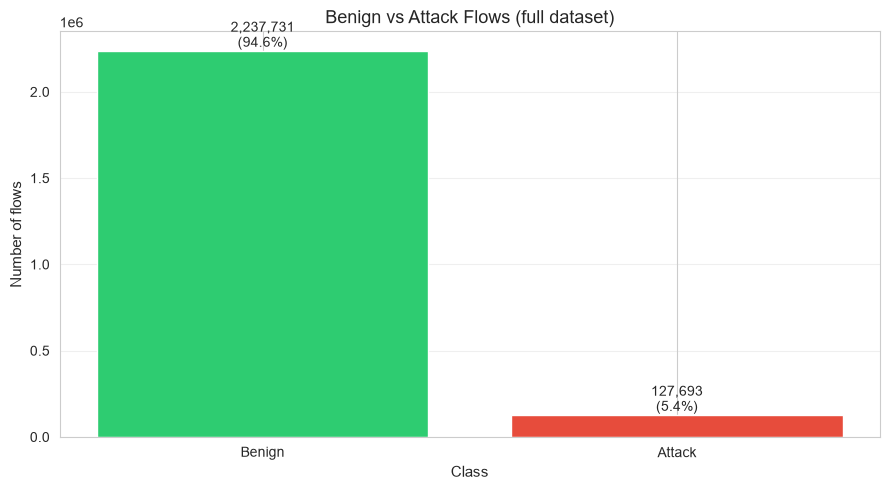

In [7]:
label_df = pd.DataFrame(
    [(int(k), v) for k, v in label_counts.items()],
    columns=['Label', 'Flows'],
)
label_df['Class'] = label_df['Label'].map({0: 'Benign', 1: 'Attack'})
label_df['Percent'] = (label_df['Flows'] / total_rows * 100).round(2)
label_df = label_df.sort_values('Flows', ascending=False)
display(label_df)

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#2ecc71' if c == 'Benign' else '#e74c3c' for c in label_df['Class']]
bars = ax.bar(label_df['Class'], label_df['Flows'], color=colors)
ax.set_xlabel('Class')
ax.set_ylabel('Number of flows')
ax.set_title('Benign vs Attack Flows (full dataset)')
for bar, pct in zip(bars, label_df['Percent']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f'{bar.get_height():,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Attack sub-type distribution (full dataset)

Attack rows only (benign removed). This is the table the rest of the notebook uses.

,Attack,Flows,PercentOfAttacks
0,Exploits,42748,33.48
1,Fuzzers,33816,26.48
2,Generic,19651,15.39
3,Reconnaissance,17074,13.37
4,DoS,5980,4.68
5,Backdoor,4659,3.65
6,Shellcode,2381,1.86
7,Analysis,1226,0.96
8,Worms,158,0.12


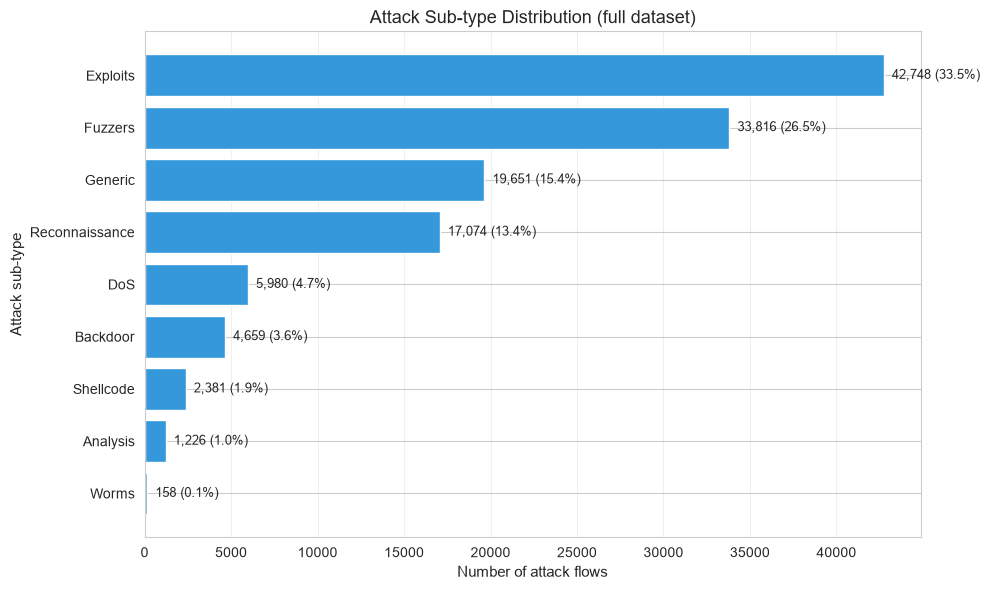

In [8]:
attack_df = pd.DataFrame(
    [(k, v) for k, v in attack_counts.items()],
    columns=['Attack', 'Flows'],
).sort_values('Flows', ascending=False)
attack_df['PercentOfAttacks'] = (attack_df['Flows'] / attack_df['Flows'].sum() * 100).round(2)
display(attack_df.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(attack_df['Attack'][::-1], attack_df['Flows'][::-1], color='#3498db')
ax.set_xlabel('Number of attack flows')
ax.set_ylabel('Attack sub-type')
ax.set_title('Attack Sub-type Distribution (full dataset)')
for i, (v, p) in enumerate(zip(attack_df['Flows'][::-1], attack_df['PercentOfAttacks'][::-1])):
    ax.text(v, i, f'  {v:,} ({p:.1f}%)', va='center', fontsize=9)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Attack ordering: sequential or mixed?

**Question:** after removing benign flows and sorting by time, do the same attacks arrive in long blocks, or are different attacks interleaved?

- `runs` = number of consecutive blocks of the same attack type.
- **Mixing index** = `(runs - 1) / (attack flows - 1)`.
  - `0.0` -> one huge block (fully sequential).
  - `1.0` -> the attack type changes at every single flow (fully mixed).

This uses the **full attack sequence**, not the first 1M rows, so all 9 attack types are included.

In [9]:
change = np.r_[True, attack_codes[1:] != attack_codes[:-1]]
run_starts = np.flatnonzero(change)
run_lengths = np.diff(np.r_[run_starts, len(attack_codes)])
run_types = attack_codes[run_starts]

n_flows = len(attack_codes)
n_runs = len(run_lengths)
mixing_index = (n_runs - 1) / (n_flows - 1)

print(f'Attack flows        : {n_flows:,}')
print(f'Consecutive blocks  : {n_runs:,}')
print(f'Mean block length   : {run_lengths.mean():,.1f} flows')
print(f'Median block length : {np.median(run_lengths):,.0f} flows')
print(f'Longest block       : {run_lengths.max():,} flows')
print(f'Mixing index        : {mixing_index:.4f}')

if mixing_index < 0.3:
    verdict = 'mostly BLOCKED / sequential'
elif mixing_index > 0.7:
    verdict = 'strongly MIXED'
else:
    verdict = 'PARTIALLY mixed'
print(f'Verdict             : {verdict}')

Attack flows        : 127,693
Consecutive blocks  : 79,724
Mean block length   : 1.6 flows
Median block length : 1 flows
Longest block       : 2,890 flows
Mixing index        : 0.6243
Verdict             : PARTIALLY mixed


In [10]:
n_types = len(attack_to_code)
run_count = np.bincount(run_types, minlength=n_types)
run_sum = np.bincount(run_types, weights=run_lengths, minlength=n_types)
run_max = np.zeros(n_types, dtype=np.int64)
np.maximum.at(run_max, run_types, run_lengths)

run_table = pd.DataFrame({
    'Runs': run_count,
    'MeanRun': np.divide(run_sum, run_count, out=np.zeros(n_types), where=run_count > 0),
    'MaxRun': run_max,
}, index=[code_to_attack[i] for i in range(n_types)])
run_table.index.name = 'Attack'
run_table = run_table.sort_values('Runs', ascending=False).round(1)
display(run_table)

,Runs,MeanRun,MaxRun
Attack,,,
Exploits,22905,1.9,66
Fuzzers,19856,1.7,95
Generic,14840,1.3,53
Reconnaissance,13316,1.3,34
DoS,4928,1.2,13
Shellcode,2073,1.1,10
Analysis,1150,1.1,4
Backdoor,498,9.4,2890
Worms,158,1.0,1


### Chronological block order

UNSW-NB15 is **not** a scenario-per-day dataset. Once benign traffic is removed and attacks are put in time order, the attack types interleave heavily, producing tens of thousands of very short blocks. Only **8 blocks reach 50 flows**; the three largest are `Backdoor`, and the rest are short bursts of other attack types. The table and Gantt chart below show those large blocks; the following cells zoom out to the full picture.

In [11]:
block_rows = []
for k, start in enumerate(run_starts):
    end = start + run_lengths[k] - 1
    block_rows.append({
        'Order': k + 1,
        'Attack': code_to_attack[int(run_types[k])],
        'Flows': int(run_lengths[k]),
        'Start': pd.to_datetime(int(attack_times[start]), unit='ms'),
        'End': pd.to_datetime(int(attack_times[end]), unit='ms'),
        'Duration_min': round((int(attack_times[end]) - int(attack_times[start])) / 60_000, 2),
    })
block_df = pd.DataFrame(block_rows)

MAJOR_MIN_FLOWS = 50
major_blocks = block_df[block_df['Flows'] >= MAJOR_MIN_FLOWS].copy().reset_index(drop=True)
major_blocks['Order'] = range(1, len(major_blocks) + 1)
print(f'Total blocks             : {len(block_df):,}')
print(f'Blocks >= {MAJOR_MIN_FLOWS} flows         : {len(major_blocks):,}')
print(f'Flows in those blocks    : {major_blocks["Flows"].sum():,} '
      f'({major_blocks["Flows"].sum() / n_flows * 100:.2f}% of attacks)')
display(major_blocks)

Total blocks             : 79,724
Blocks >= 50 flows         : 8
Flows in those blocks    : 4,261 (3.34% of attacks)


,Order,Attack,Flows,Start,End,Duration_min
0,1,Backdoor,2890,2015-02-18 00:49:31.199,2015-02-18 01:04:56.111,15.42
1,2,Fuzzers,57,2015-02-18 02:53:55.404,2015-02-18 02:54:45.050,0.83
2,3,Fuzzers,95,2015-02-18 04:32:18.649,2015-02-18 04:33:17.603,0.98
3,4,Exploits,66,2015-02-18 05:18:26.020,2015-02-18 05:18:31.720,0.10
4,5,Generic,53,2015-02-18 08:29:42.329,2015-02-18 08:30:16.346,0.57
5,6,Fuzzers,60,2015-02-18 09:32:58.649,2015-02-18 09:33:25.907,0.45
6,7,Backdoor,145,2015-02-18 10:29:18.917,2015-02-18 10:30:51.395,1.54
7,8,Backdoor,895,2015-02-18 12:22:46.426,2015-02-18 12:29:24.917,6.64


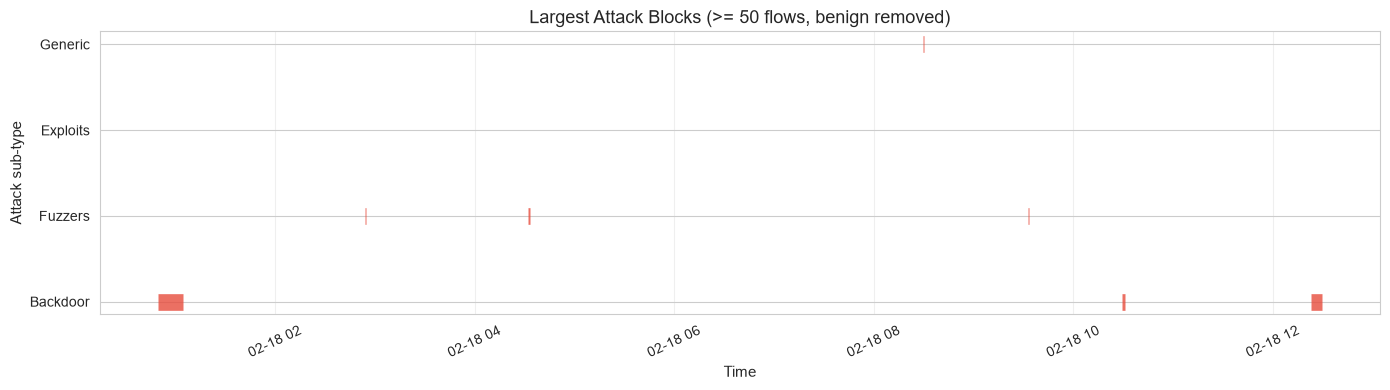

In [12]:
fig, ax = plt.subplots(figsize=(14, 4))
for _, row in major_blocks.iterrows():
    ax.hlines(row['Attack'], row['Start'], row['End'],
              linewidth=12, color='#e74c3c', alpha=0.8)
ax.set_xlabel('Time')
ax.set_ylabel('Attack sub-type')
ax.set_title(f'Largest Attack Blocks (>= {MAJOR_MIN_FLOWS} flows, benign removed)')
ax.grid(axis='x', alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

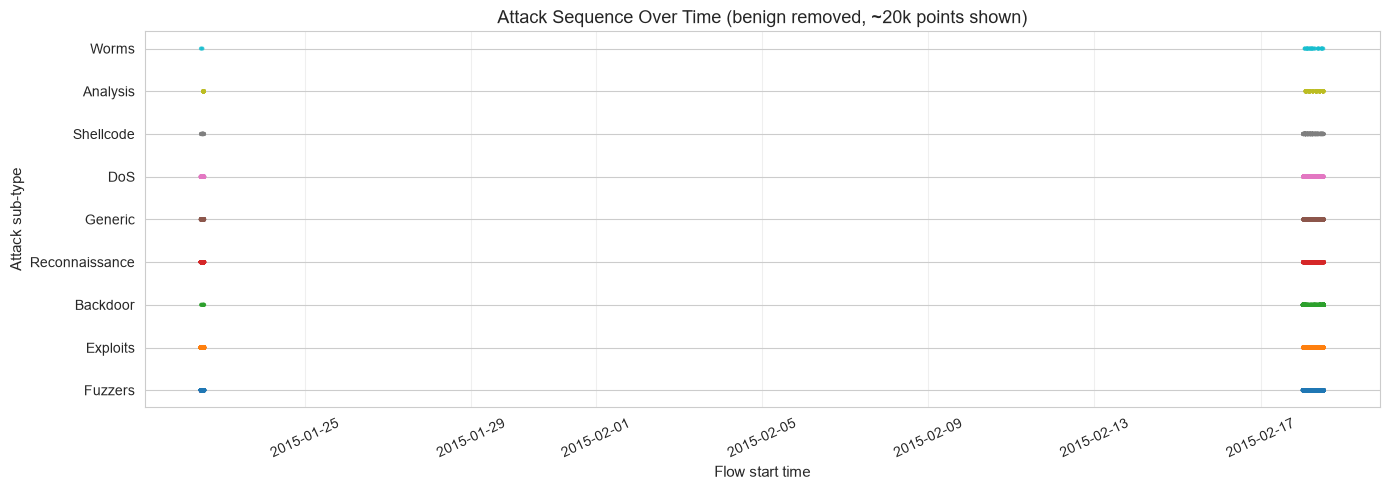

In [13]:
step = max(1, n_flows // 20_000)
tl_time = pd.to_datetime(attack_times[::step], unit='ms')
tl_code = attack_codes[::step]

fig, ax = plt.subplots(figsize=(14, 5))
ax.scatter(tl_time, tl_code, c=tl_code, cmap='tab10', s=4, alpha=0.75)
ax.set_yticks(range(n_types))
ax.set_yticklabels([code_to_attack[i] for i in range(n_types)])
ax.set_xlabel('Flow start time')
ax.set_ylabel('Attack sub-type')
ax.set_title('Attack Sequence Over Time (benign removed, ~20k points shown)')
ax.grid(axis='x', alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

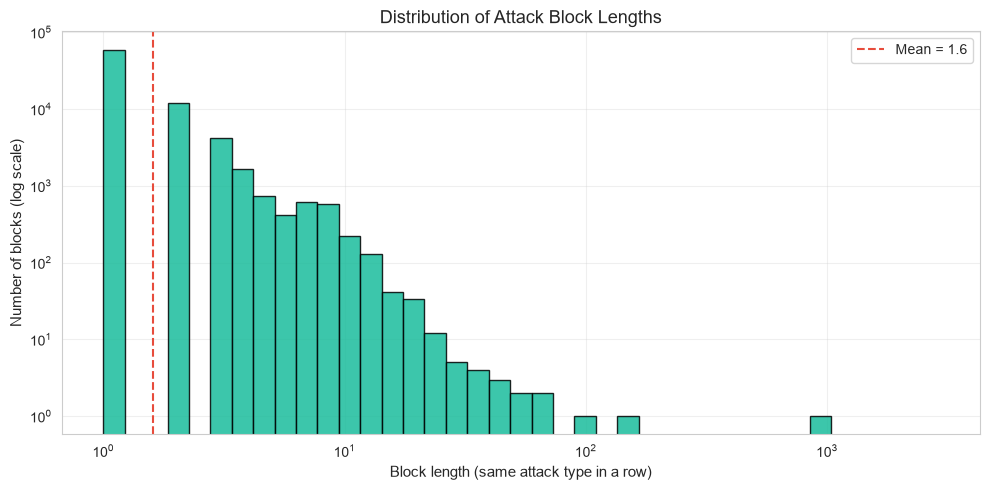

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.logspace(0, np.log10(max(int(run_lengths.max()), 2)), 40)
ax.hist(run_lengths, bins=bins, color='#1abc9c', edgecolor='black', alpha=0.85)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Block length (same attack type in a row)')
ax.set_ylabel('Number of blocks (log scale)')
ax.set_title('Distribution of Attack Block Lengths')
ax.axvline(run_lengths.mean(), color='#e74c3c', linestyle='--',
           label=f'Mean = {run_lengths.mean():,.1f}')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,Fuzzers,Exploits,Backdoor,Reconnaissance,Generic,DoS,Shellcode,Analysis,Worms
Fuzzers,41.3,27.0,0.4,12.2,12.3,4.1,1.8,0.7,0.2
Exploits,21.1,46.4,0.4,11.6,14.1,4.1,1.4,0.8,0.1
Backdoor,3.2,3.5,89.3,1.0,2.0,0.7,0.1,0.1,0.0
Reconnaissance,24.7,27.8,0.3,22.0,17.4,4.4,1.9,1.5,0.1
Generic,20.8,31.0,0.5,15.2,24.5,4.4,2.2,1.2,0.2
DoS,24.5,28.9,0.3,11.4,14.7,17.6,1.5,0.8,0.2
Shellcode,25.2,26.6,0.1,12.6,18.1,3.7,12.9,0.7,0.0
Analysis,19.8,30.0,0.4,18.4,19.1,4.6,1.5,6.2,0.0
Worms,43.7,31.0,0.0,8.9,11.4,3.8,0.6,0.6,0.0


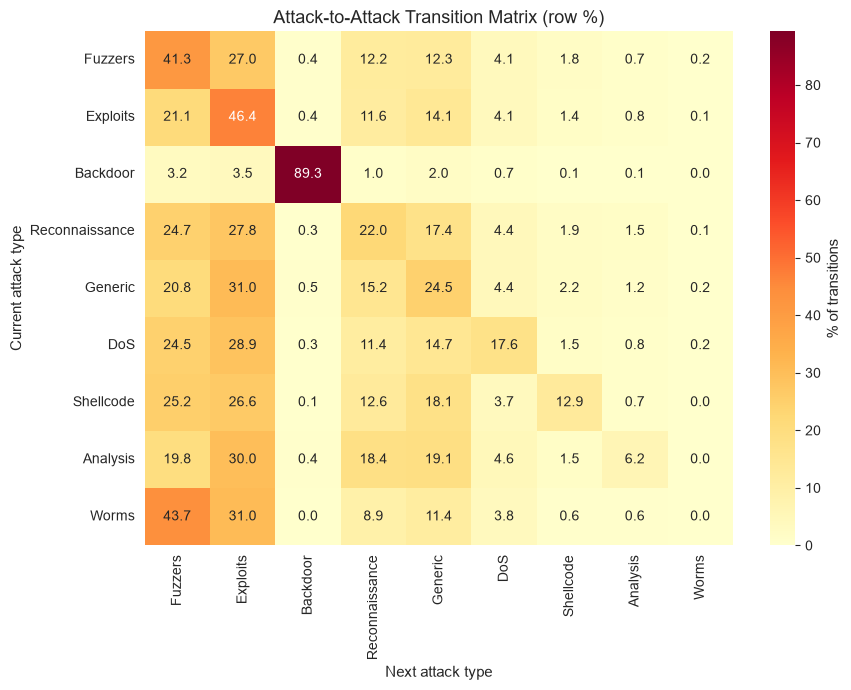

In [15]:
pair_index = attack_codes[:-1].astype(np.int64) * n_types + attack_codes[1:]
trans = np.bincount(pair_index, minlength=n_types * n_types).reshape(n_types, n_types)
row_sums = trans.sum(axis=1, keepdims=True)
trans_pct = np.divide(trans, row_sums,
                      out=np.zeros_like(trans, dtype=float), where=row_sums > 0) * 100

names = [code_to_attack[i] for i in range(n_types)]
trans_df = pd.DataFrame(trans_pct.round(1), index=names, columns=names)
display(trans_df)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(trans_df, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax,
            cbar_kws={'label': '% of transitions'})
ax.set_xlabel('Next attack type')
ax.set_ylabel('Current attack type')
ax.set_title('Attack-to-Attack Transition Matrix (row %)')
plt.tight_layout()
plt.show()

### Attack volume by capture day and hour

Attacks occur on only two capture days. The first heatmap shows how the days split across attack types; the second shows the hour-of-day profile within each day.

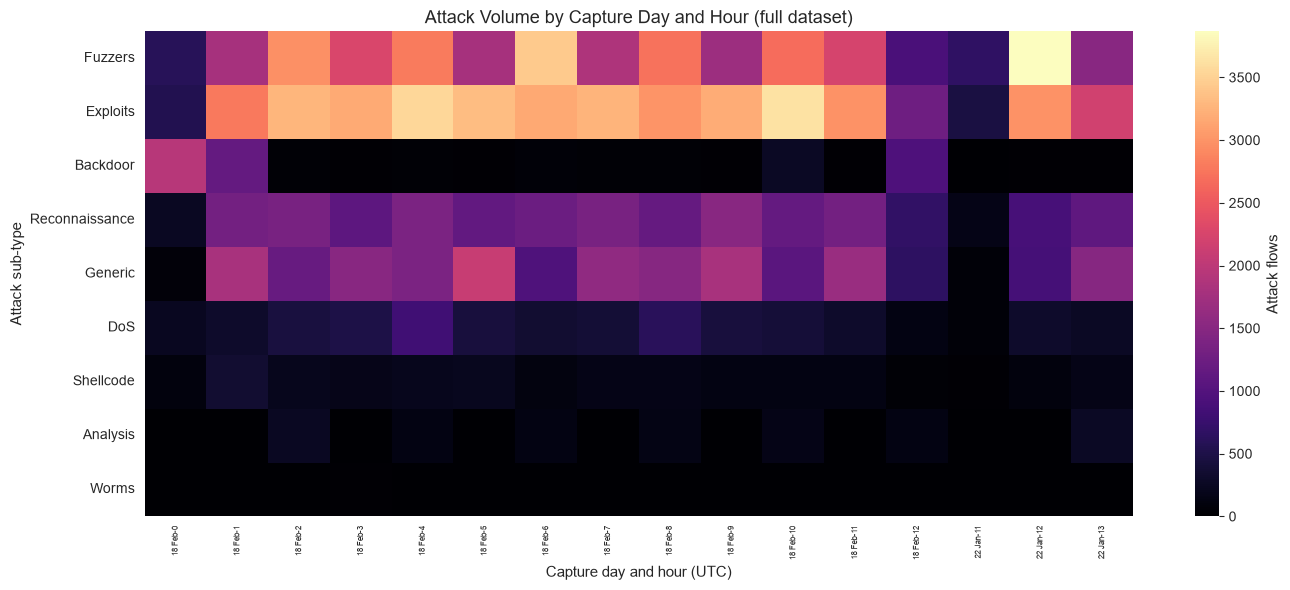

In [16]:
attack_hour = pd.to_datetime(attack_times, unit='ms').hour
date_labels = pd.to_datetime(attack_times, unit='ms').strftime('%d %b')
day_hour = pd.DataFrame({'Day': date_labels, 'Hour': attack_hour, 'Code': attack_codes})
day_hour_table = pd.crosstab([day_hour['Day'], day_hour['Hour']], day_hour['Code'])
day_hour_table.columns = [code_to_attack[c] for c in day_hour_table.columns]

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(day_hour_table.T, cmap='magma', ax=ax,
            cbar_kws={'label': 'Attack flows'})
ax.set_xlabel('Capture day and hour (UTC)')
ax.set_ylabel('Attack sub-type')
ax.set_title('Attack Volume by Capture Day and Hour (full dataset)')
plt.xticks(rotation=90, fontsize=6)
plt.tight_layout()
plt.show()

## 8. Check all attacks at once - or one at a time

The table below has **one row per attack type and a `Selected` column**. Change `SELECTION` to analyse everything together or a single attack separately.

- `'all'` -> every attack type
- `'Exploits'` -> one attack type
- `['Exploits', 'Worms']` -> any subset

In [17]:
all_attacks = attack_df['Attack'].tolist()
SELECTION = 'all'          # 'all', 'Exploits', or ['Exploits', 'Worms']

if SELECTION == 'all':
    selected_attacks = all_attacks
elif isinstance(SELECTION, str):
    selected_attacks = [SELECTION]
else:
    selected_attacks = list(SELECTION)

unknown = [a for a in selected_attacks if a not in all_attacks]
if unknown:
    raise ValueError(f'Unknown attack(s): {unknown}. Choose from {all_attacks}')

print('All attack types :', all_attacks)
print('Selected         :', selected_attacks)

All attack types : ['Exploits', 'Fuzzers', 'Generic', 'Reconnaissance', 'DoS', 'Backdoor', 'Shellcode', 'Analysis', 'Worms']
Selected         : ['Exploits', 'Fuzzers', 'Generic', 'Reconnaissance', 'DoS', 'Backdoor', 'Shellcode', 'Analysis', 'Worms']


### Per-attack summary table

One row per attack type. **Flow counts, shares and block statistics use the full scan**; **unique IPs and mean feature values use the stratified sample** (up to 20,000 flows per attack). The `Selected` column shows which rows the next plots use.

In [18]:
summary = pd.DataFrame(index=all_attacks)
summary.index.name = 'Attack'
summary['Flows'] = [attack_counts[a] for a in all_attacks]
summary['ShareOfAttacks_%'] = (summary['Flows'] / summary['Flows'].sum() * 100).round(2)
summary['Runs'] = run_table['Runs']
summary['MeanRun'] = run_table['MeanRun']
summary['MaxRun'] = run_table['MaxRun']
summary['UniqueSrcIPs'] = df_attacks.groupby('Attack')['IPV4_SRC_ADDR'].nunique()
summary['UniqueDstIPs'] = df_attacks.groupby('Attack')['IPV4_DST_ADDR'].nunique()
summary['MeanDuration_ms'] = df_attacks.groupby('Attack')['FLOW_DURATION_MILLISECONDS'].mean().round(1)
summary['MeanIN_BYTES'] = df_attacks.groupby('Attack')['IN_BYTES'].mean().round(1)
summary['MeanOUT_BYTES'] = df_attacks.groupby('Attack')['OUT_BYTES'].mean().round(1)
summary['MeanIN_PKTS'] = df_attacks.groupby('Attack')['IN_PKTS'].mean().round(1)
summary['MeanOUT_PKTS'] = df_attacks.groupby('Attack')['OUT_PKTS'].mean().round(1)
summary['Selected'] = summary.index.isin(selected_attacks)
summary = summary.fillna(0).sort_values('Flows', ascending=False)
display(summary)

,Flows,ShareOfAttacks_%,Runs,MeanRun,MaxRun,UniqueSrcIPs,UniqueDstIPs,MeanDuration_ms,MeanIN_BYTES,MeanOUT_BYTES,MeanIN_PKTS,MeanOUT_PKTS,Selected
Attack,,,,,,,,,,,,,
Exploits,42748,33.48,22905,1.9,66,4,10,1322.3,30267.1,15379.8,33.7,22.6,True
Fuzzers,33816,26.48,19856,1.7,95,4,10,937.4,6457.9,476.2,12.4,6.2,True
Generic,19651,15.39,14840,1.3,53,4,10,632.6,2745.5,10525.0,7.1,9.7,True
Reconnaissance,17074,13.37,13316,1.3,34,4,10,789.4,1434.5,508.3,7.6,4.7,True
DoS,5980,4.68,4928,1.2,13,4,10,2052.2,39863.7,50704.0,47.4,50.6,True
Backdoor,4659,3.65,498,9.4,2890,4,10,1751.2,14947.4,19318.6,21.8,22.3,True
Shellcode,2381,1.86,2073,1.1,10,4,10,496.0,1108.6,149.8,6.7,3.5,True
Analysis,1226,0.96,1150,1.1,4,4,7,990.9,820.0,1196.4,10.1,8.8,True
Worms,158,0.12,158,1.0,1,4,10,1280.7,2232.0,72814.2,17.6,59.8,True


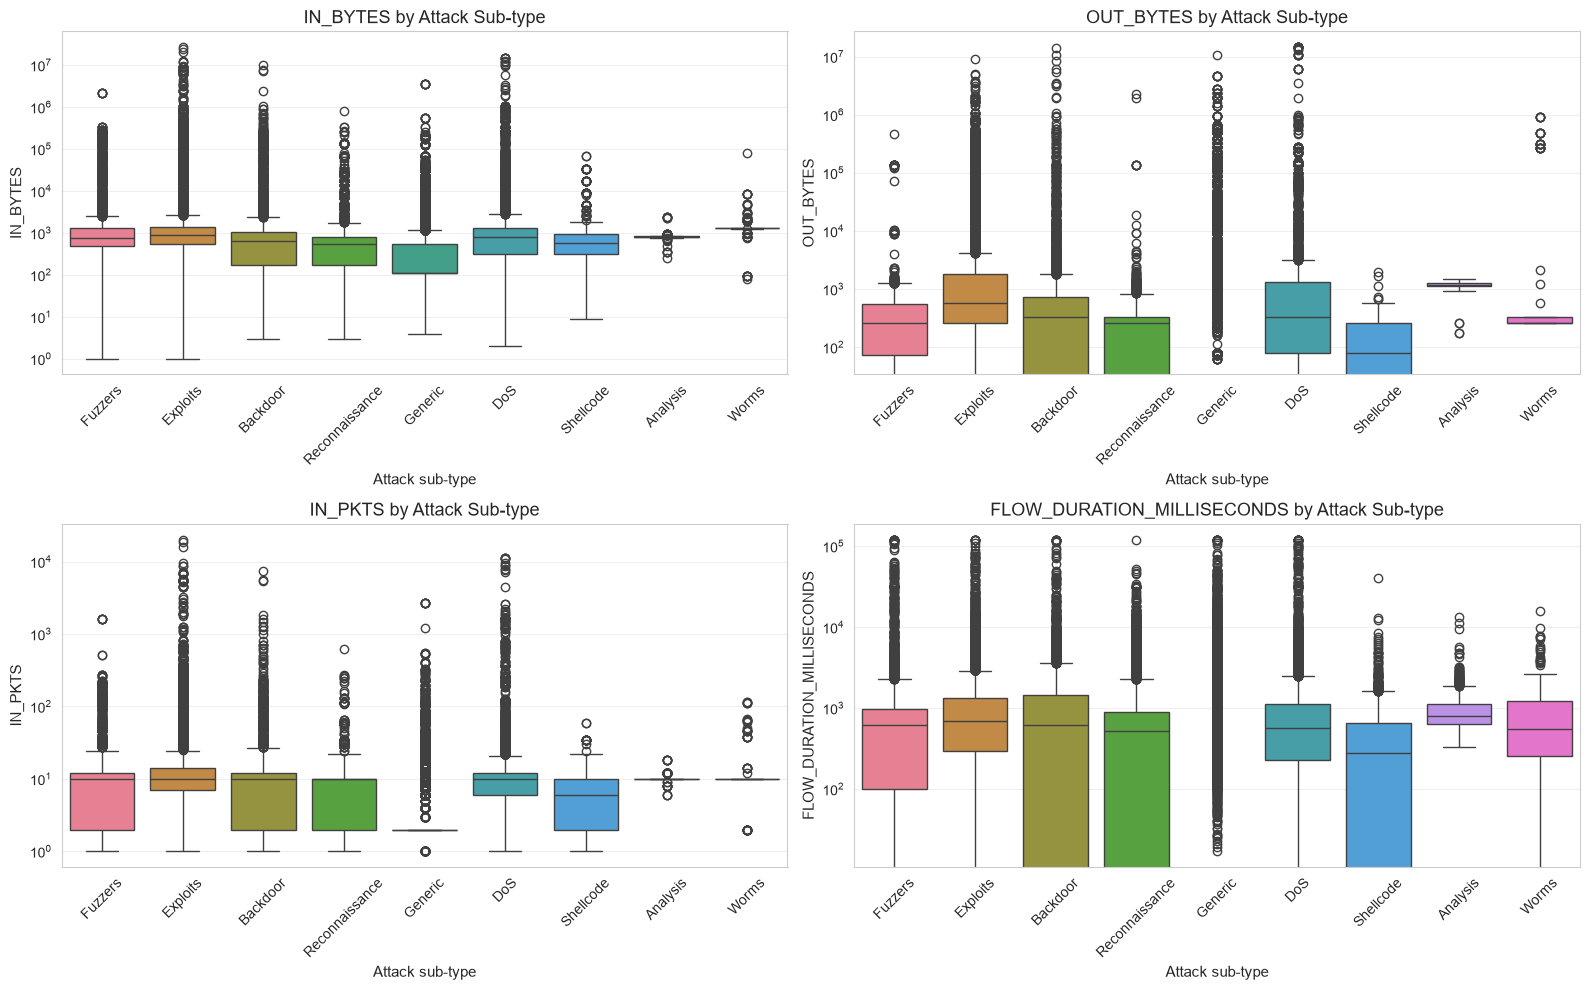

In [19]:
compare_attacks = df_attacks[df_attacks['Attack'].isin(selected_attacks)]
features = ['IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'FLOW_DURATION_MILLISECONDS']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, feat in zip(axes.ravel(), features):
    sns.boxplot(data=compare_attacks, x='Attack', y=feat, ax=ax, palette='husl')
    ax.set_yscale('log')
    ax.set_xlabel('Attack sub-type')
    ax.set_ylabel(feat)
    ax.set_title(f'{feat} by Attack Sub-type')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

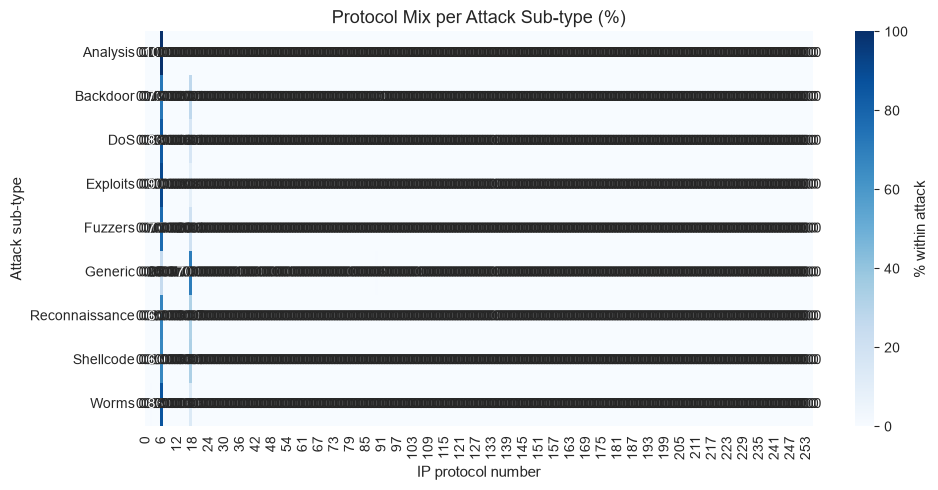

In [20]:
proto_attack = pd.crosstab(compare_attacks['Attack'], compare_attacks['PROTOCOL'],
                           normalize='index') * 100

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(proto_attack.round(1), annot=True, fmt='.1f', cmap='Blues', ax=ax,
            cbar_kws={'label': '% within attack'})
ax.set_xlabel('IP protocol number')
ax.set_ylabel('Attack sub-type')
ax.set_title('Protocol Mix per Attack Sub-type (%)')
plt.tight_layout()
plt.show()

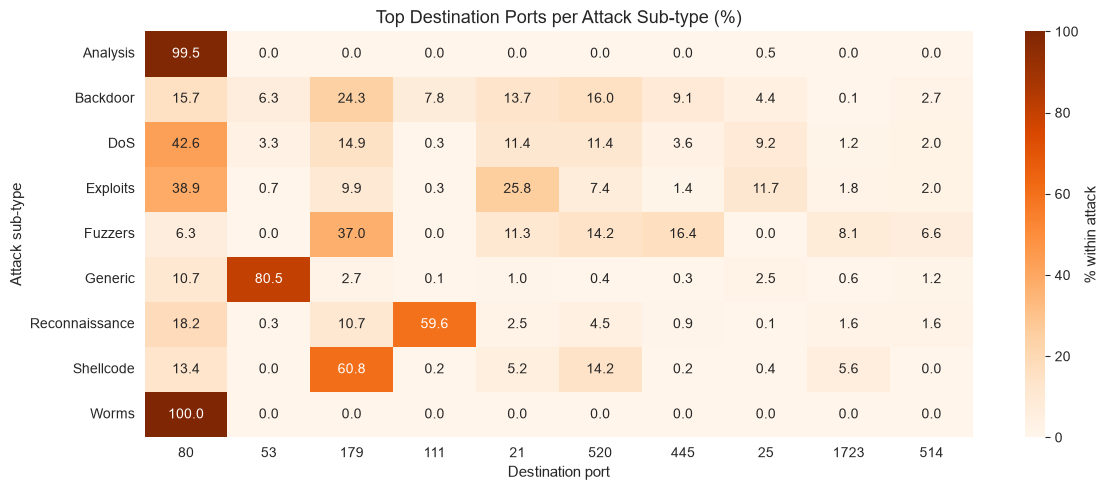

In [21]:
top_ports = compare_attacks['L4_DST_PORT'].value_counts().head(10).index
port_table = pd.crosstab(compare_attacks['Attack'], compare_attacks['L4_DST_PORT'])
port_table = port_table.reindex(columns=top_ports, fill_value=0)
port_pct = port_table.div(port_table.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(port_pct.round(1), annot=True, fmt='.1f', cmap='Oranges', ax=ax,
            cbar_kws={'label': '% within attack'})
ax.set_xlabel('Destination port')
ax.set_ylabel('Attack sub-type')
ax.set_title('Top Destination Ports per Attack Sub-type (%)')
plt.tight_layout()
plt.show()

## 9. Benign vs attack statistics

Build a comparison table from a benign sample plus the stratified attack sample, adding a `Class` column (`Benign` or the attack name) so every row is easy to filter.

In [22]:
benign_pool = df_sample[df_sample['Label'] == 0]
benign_sample = benign_pool.sample(n=min(50_000, len(benign_pool)), random_state=42)

df_compare = pd.concat([benign_sample, df_attacks], ignore_index=True)
df_compare['Class'] = df_compare['Attack']
df_compare.loc[df_compare['Label'] == 0, 'Class'] = 'Benign'

key_features = [
    'FLOW_DURATION_MILLISECONDS', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS',
    'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'MIN_TTL', 'MAX_TTL',
    'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT',
]

stats_by_label = df_compare.groupby('Label')[key_features].agg(['mean', 'median', 'std'])
stats_by_label.index = stats_by_label.index.map({0: 'Benign', 1: 'Attack'})
display(stats_by_label.round(2))

FLOW_DURATION_MILLISECONDS                  IN_BYTES          \
                             mean median      std      mean  median   
Label                                                                 
Benign                     566.32   27.0  3524.47   3814.62  1684.0   
Attack                    1032.96  471.0  4626.15  12344.80   576.0   

                  OUT_BYTES                    IN_PKTS  ... MIN_TTL MAX_TTL  \
              std      mean  median        std    mean  ...     std    mean   
Label                                                   ...                   
Benign    8156.12  37344.53  2510.0  158151.88   36.55  ...    5.17   31.20   
Attack  266520.75  10305.93   256.0  222472.46   17.64  ...   78.49  214.16   

                     LONGEST_FLOW_PKT                SHORTEST_FLOW_PKT         \
       median    std             mean median     std              mean median   
Label                                                                           
Benign   32.0   5.29           723.82  510.0  617.66             57.39   52.0   
Attack  254.0  78.32           405.06  117.0  496.27             80.67   40.0   

                
           std  
Label           
Benign   14.61  
Attack  148.74  

[2 rows x 33 columns]

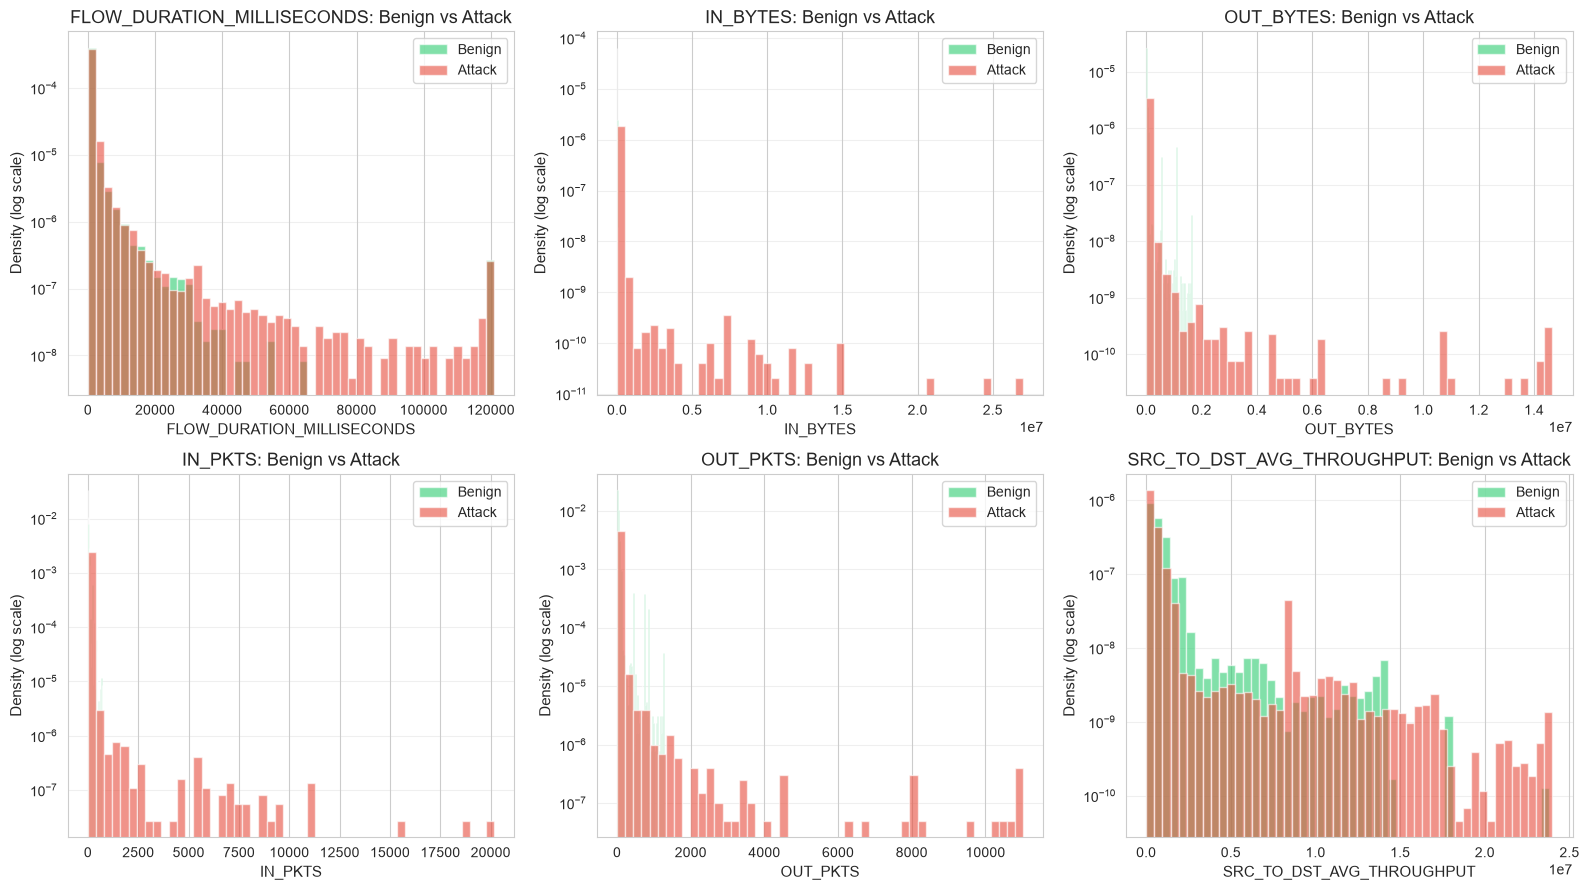

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feat in zip(axes.ravel(), key_features[:6]):
    for label, color in [(0, '#2ecc71'), (1, '#e74c3c')]:
        vals = df_compare.loc[df_compare['Label'] == label, feat]
        ax.hist(vals, bins=50, alpha=0.6, density=True, color=color,
                label='Benign' if label == 0 else 'Attack')
    ax.set_yscale('log')
    ax.set_xlabel(feat)
    ax.set_ylabel('Density (log scale)')
    ax.set_title(f'{feat}: Benign vs Attack')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

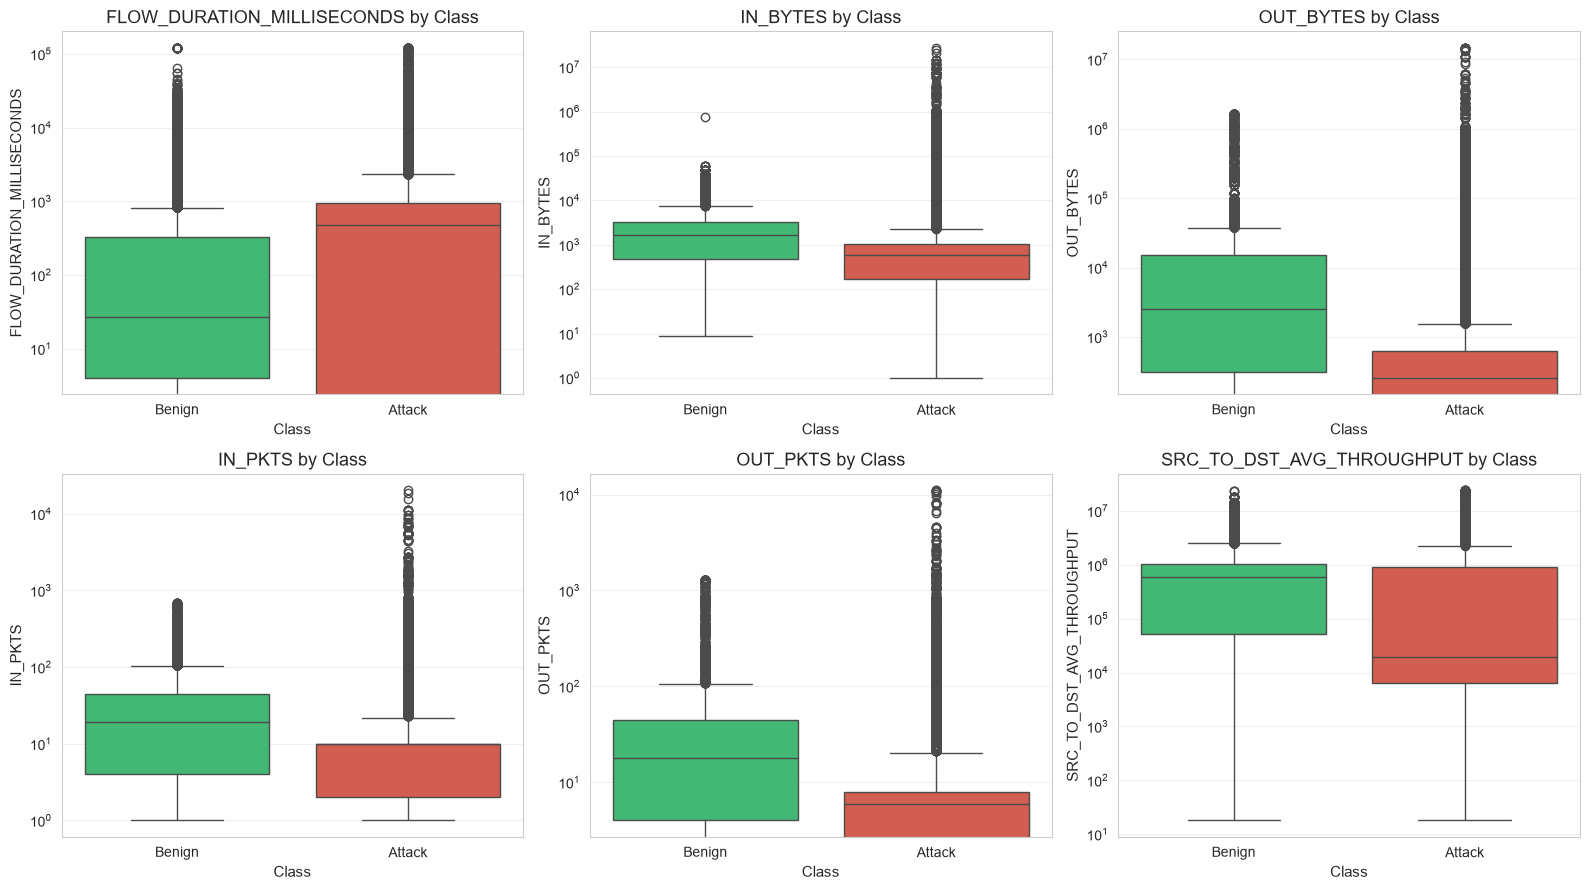

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feat in zip(axes.ravel(), key_features[:6]):
    sns.boxplot(data=df_compare, x='Label', y=feat, ax=ax,
                palette=['#2ecc71', '#e74c3c'])
    ax.set_yscale('log')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Benign', 'Attack'])
    ax.set_xlabel('Class')
    ax.set_ylabel(feat)
    ax.set_title(f'{feat} by Class')
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Protocol analysis

Full-file IP protocol counts, plus the protocol mix inside each attack type.

,Protocol,Flows,Name,Percent
0,6,1805270,TCP,76.32
1,17,556557,UDP,23.53
2,89,1407,OSPF,0.06
3,1,401,ICMP,0.02
4,132,73,SCTP,0.00
5,2,33,IGMP,0.00
6,47,14,GRE,0.00
7,103,14,Other,0.00
8,33,13,Other,0.00
9,53,13,Other,0.00


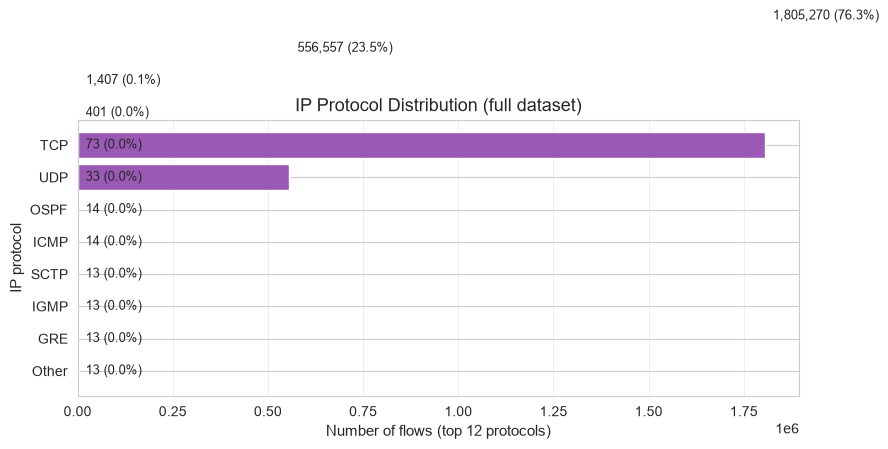

In [25]:
PROTOCOL_MAP = {1: 'ICMP', 2: 'IGMP', 6: 'TCP', 17: 'UDP', 47: 'GRE',
                50: 'ESP', 51: 'AH', 58: 'ICMPv6', 89: 'OSPF', 132: 'SCTP'}

proto_df = pd.DataFrame(proto_counts.items(), columns=['Protocol', 'Flows'])
proto_df['Protocol'] = pd.to_numeric(proto_df['Protocol'], errors='coerce').fillna(-1).astype(int)
proto_df['Name'] = proto_df['Protocol'].map(PROTOCOL_MAP).fillna('Other')
proto_df['Percent'] = (proto_df['Flows'] / total_rows * 100).round(2)
proto_df = proto_df.sort_values('Flows', ascending=False).head(12)
display(proto_df.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(proto_df['Name'][::-1], proto_df['Flows'][::-1], color='#9b59b6')
ax.set_xlabel('Number of flows (top 12 protocols)')
ax.set_ylabel('IP protocol')
ax.set_title('IP Protocol Distribution (full dataset)')
for i, (v, p) in enumerate(zip(proto_df['Flows'][::-1], proto_df['Percent'][::-1])):
    ax.text(v, i, f'  {v:,} ({p:.1f}%)', va='center', fontsize=9)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Port analysis

Top source and destination ports over the full file, using well-known service names where possible.

,Port,Flows,Service
0,21,483119,FTP
1,53,380128,DNS
2,80,201574,HTTP
3,6881,115744,Other
4,5190,110066,Other
5,111,87307,Other
6,25,80427,SMTP
7,22,46399,SSH
8,143,46329,IMAP
9,179,18760,Other


,Port,Flows,Service
0,1043,19714,Ephemeral/Other
1,47439,19675,Ephemeral/Other
2,0,3530,Ephemeral/Other
3,21,918,FTP
4,53,559,DNS
5,80,515,HTTP
6,6881,250,Ephemeral/Other
7,5190,179,Ephemeral/Other
8,25,156,SMTP
9,5060,147,Ephemeral/Other


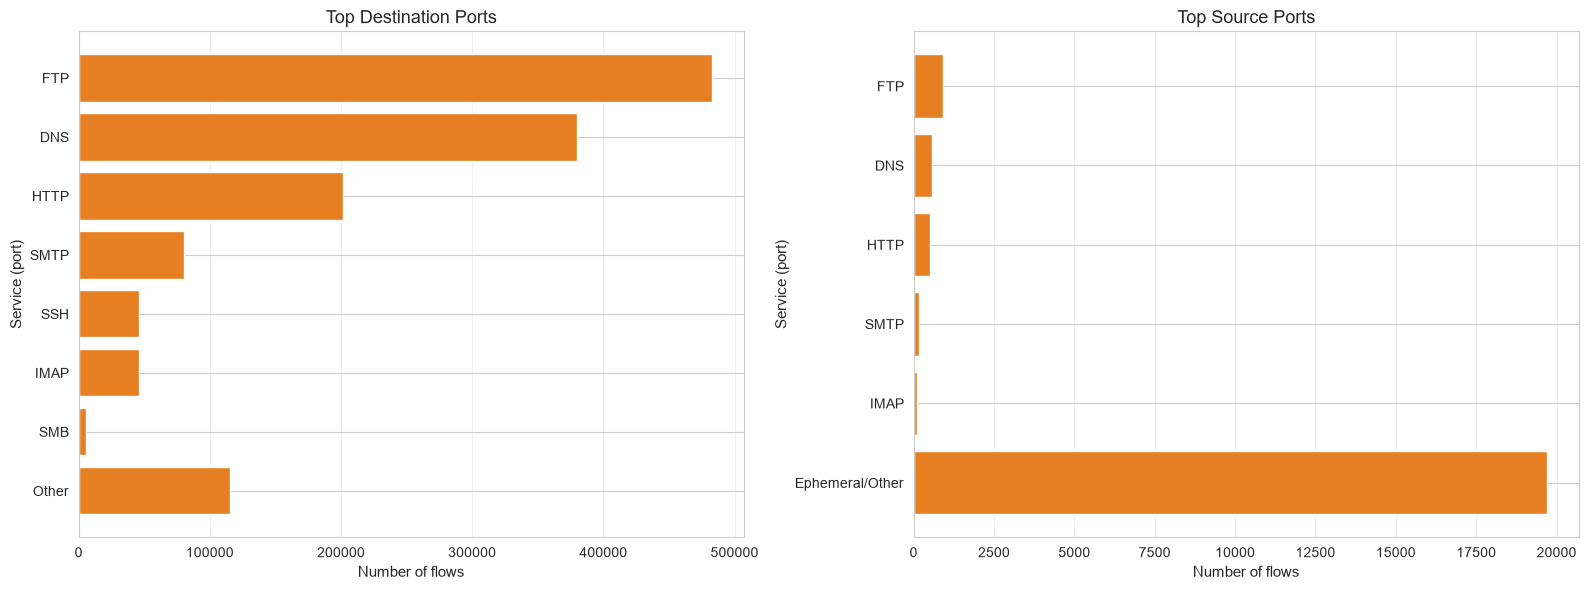

In [26]:
WELL_KNOWN_PORTS = {
    20: 'FTP-DATA', 21: 'FTP', 22: 'SSH', 23: 'TELNET', 25: 'SMTP',
    53: 'DNS', 67: 'DHCP', 68: 'DHCP', 69: 'TFTP', 80: 'HTTP',
    110: 'POP3', 123: 'NTP', 139: 'NetBIOS', 143: 'IMAP', 161: 'SNMP',
    443: 'HTTPS', 445: 'SMB', 993: 'IMAPS', 995: 'POP3S', 1433: 'MSSQL',
    3306: 'MySQL', 3389: 'RDP', 5432: 'PostgreSQL', 5900: 'VNC',
    8080: 'HTTP-Alt', 27017: 'MongoDB',
}

dst_df = pd.DataFrame(dst_port_counts.items(), columns=['Port', 'Flows'])
dst_df['Service'] = dst_df['Port'].map(WELL_KNOWN_PORTS).fillna('Other')
dst_df = dst_df.sort_values('Flows', ascending=False).head(15)

src_df = pd.DataFrame(src_port_counts.items(), columns=['Port', 'Flows'])
src_df['Service'] = src_df['Port'].map(WELL_KNOWN_PORTS).fillna('Ephemeral/Other')
src_df = src_df.sort_values('Flows', ascending=False).head(15)

display(dst_df.reset_index(drop=True))
display(src_df.reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, frame, title in [(axes[0], dst_df, 'Top Destination Ports'),
                         (axes[1], src_df, 'Top Source Ports')]:
    ax.barh(frame['Service'][::-1], frame['Flows'][::-1], color='#e67e22')
    ax.set_xlabel('Number of flows')
    ax.set_ylabel('Service (port)')
    ax.set_title(title)
    ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## 12. IP address analysis

How many endpoints are there, which IPs dominate, and how many unique IPs each attack type touches.

Unique source IPs      : 38
Unique destination IPs : 38


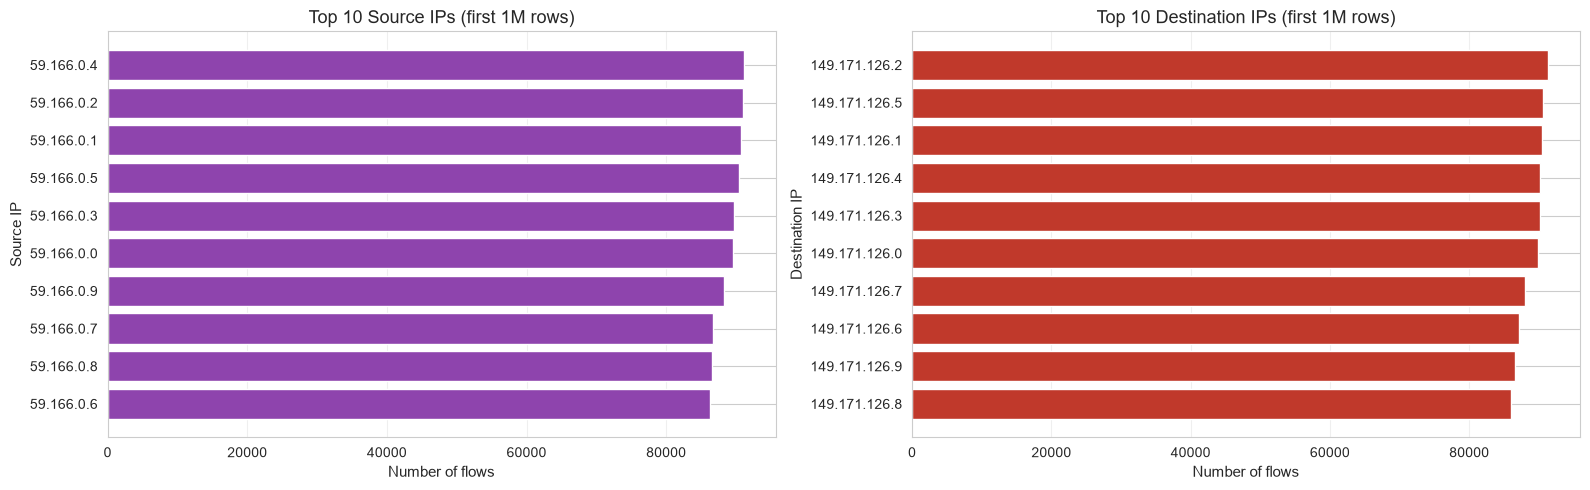

,UniqueSrcIPs,UniqueDstIPs
Attack,,
Analysis,4,7
Backdoor,4,10
DoS,4,10
Exploits,4,10
Fuzzers,4,10
Generic,4,10
Reconnaissance,4,10
Shellcode,4,10
Worms,4,10


In [27]:
print(f'Unique source IPs      : {df_sample["IPV4_SRC_ADDR"].nunique():,}')
print(f'Unique destination IPs : {df_sample["IPV4_DST_ADDR"].nunique():,}')

top_src = df_sample['IPV4_SRC_ADDR'].value_counts().head(10)
top_dst = df_sample['IPV4_DST_ADDR'].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].barh(top_src.index[::-1], top_src.values[::-1], color='#8e44ad')
axes[0].set_xlabel('Number of flows')
axes[0].set_ylabel('Source IP')
axes[0].set_title('Top 10 Source IPs (first 1M rows)')
axes[0].grid(axis='x', alpha=0.3)

axes[1].barh(top_dst.index[::-1], top_dst.values[::-1], color='#c0392b')
axes[1].set_xlabel('Number of flows')
axes[1].set_ylabel('Destination IP')
axes[1].set_title('Top 10 Destination IPs (first 1M rows)')
axes[1].grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

attack_ips = df_attacks.groupby('Attack')[['IPV4_SRC_ADDR', 'IPV4_DST_ADDR']].nunique()
attack_ips.columns = ['UniqueSrcIPs', 'UniqueDstIPs']
display(attack_ips.sort_values('UniqueSrcIPs', ascending=False))

## 13. Temporal analysis

Flow volume by hour of day and over the capture timeline. Note the file is not time-ordered, so plots are built from the timestamps themselves.

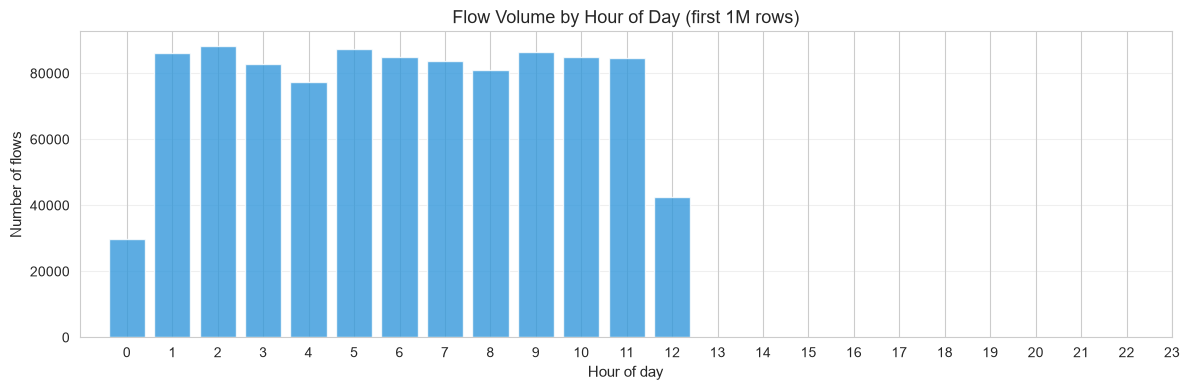

In [28]:
df_sample['flow_start_dt'] = pd.to_datetime(df_sample['FLOW_START_MILLISECONDS'], unit='ms')
hourly = df_sample['flow_start_dt'].dt.hour.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(hourly.index, hourly.values, color='#3498db', alpha=0.8)
ax.set_xlabel('Hour of day')
ax.set_ylabel('Number of flows')
ax.set_title('Flow Volume by Hour of Day (first 1M rows)')
ax.set_xticks(range(24))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

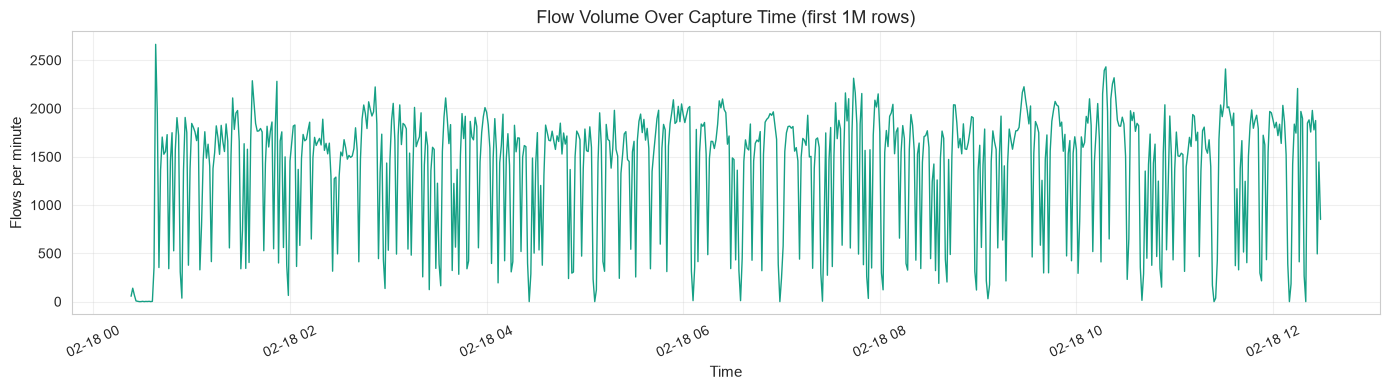

In [29]:
per_minute = df_sample.set_index('flow_start_dt').resample('1min').size()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(per_minute.index, per_minute.values, color='#16a085', linewidth=1)
ax.set_xlabel('Time')
ax.set_ylabel('Flows per minute')
ax.set_title('Flow Volume Over Capture Time (first 1M rows)')
ax.grid(alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

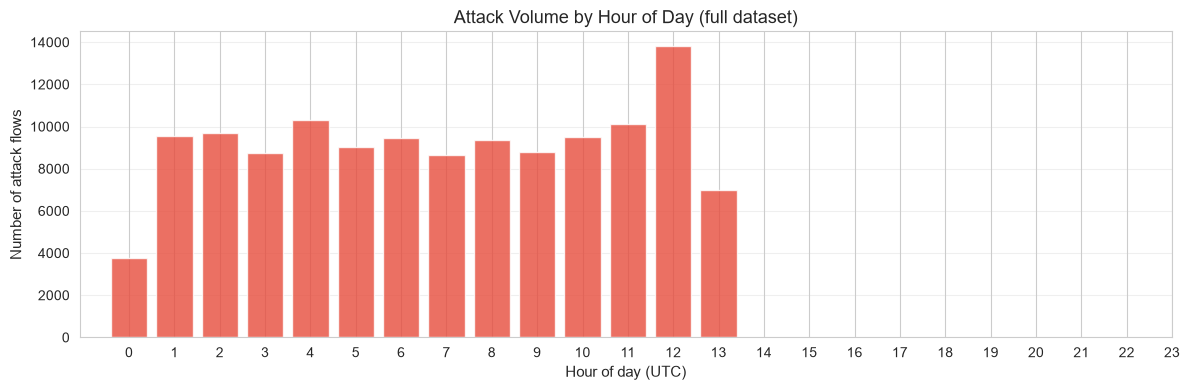

In [30]:
attack_hour_series = pd.Series(pd.to_datetime(attack_times, unit='ms').hour).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(attack_hour_series.index, attack_hour_series.values, color='#e74c3c', alpha=0.8)
ax.set_xlabel('Hour of day (UTC)')
ax.set_ylabel('Number of attack flows')
ax.set_title('Attack Volume by Hour of Day (full dataset)')
ax.set_xticks(range(24))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 14. Feature correlation

Correlation among key numeric features. Strongly correlated pairs are redundant for modelling.

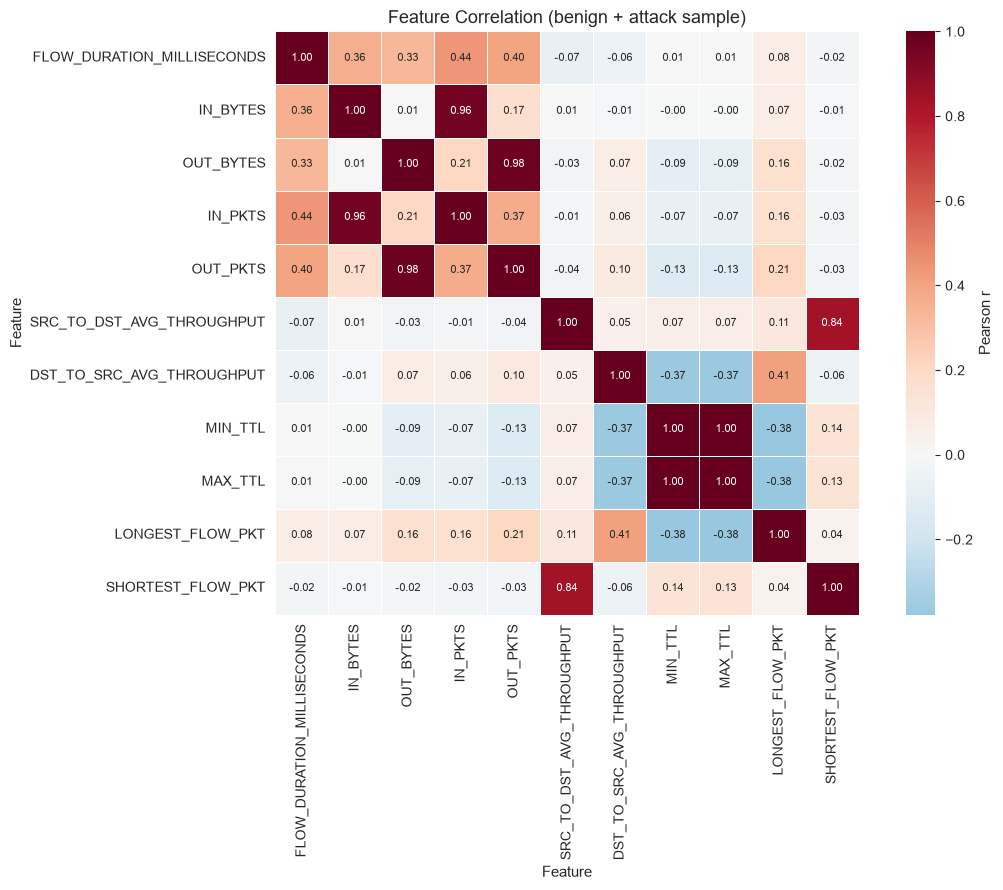

Pairs with |r| > 0.8:


,Feature 1,Feature 2,r
0,IN_BYTES,IN_PKTS,0.964
1,OUT_BYTES,OUT_PKTS,0.979
2,SRC_TO_DST_AVG_THROUGHPUT,SHORTEST_FLOW_PKT,0.839
3,MIN_TTL,MAX_TTL,1.000


In [31]:
corr = df_compare[key_features].corr()

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True,
            linewidths=0.5, ax=ax, annot_kws={'size': 8},
            cbar_kws={'label': 'Pearson r'})
ax.set_xlabel('Feature')
ax.set_ylabel('Feature')
ax.set_title('Feature Correlation (benign + attack sample)')
plt.tight_layout()
plt.show()

high = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        value = corr.iloc[i, j]
        if abs(value) > 0.8:
            high.append({'Feature 1': corr.columns[i],
                         'Feature 2': corr.columns[j],
                         'r': round(value, 3)})
print('Pairs with |r| > 0.8:')
display(pd.DataFrame(high) if high else pd.DataFrame({'Note': ['None found']}))

## 15. Missing and infinite values

Check the sample for missing (`NaN`) and infinite (`inf`) values. Unlike NF-ToN-IoT v3 and NF-CICIDS2018 v3, UNSW-NB15 **does** contain some: the two bytes-per-second columns (`SRC_TO_DST_SECOND_BYTES`, `DST_TO_SRC_SECOND_BYTES`) hold both missing and infinite values, which must be cleaned before modelling.

In [32]:
missing = df_sample.isnull().sum()
missing_df = (missing[missing > 0]
              .rename('MissingCount')
              .to_frame())
missing_df['MissingPercent'] = (missing_df['MissingCount'] / len(df_sample) * 100).round(4)
print(f'Columns with missing values: {len(missing_df)}')
display(missing_df.sort_values('MissingCount', ascending=False) if len(missing_df) else pd.DataFrame({'Note': ['No missing values']}))

numeric = df_sample.select_dtypes(include=[np.number])
inf_counts = np.isinf(numeric).sum()
inf_df = inf_counts[inf_counts > 0].rename('InfiniteCount').to_frame()
print(f'Columns with infinite values: {len(inf_df)}')
display(inf_df.sort_values('InfiniteCount', ascending=False) if len(inf_df) else pd.DataFrame({'Note': ['No infinite values']}))

Columns with missing values: 1


,MissingCount,MissingPercent
SRC_TO_DST_SECOND_BYTES,44477,4.4477


Columns with infinite values: 2


,InfiniteCount
DST_TO_SRC_SECOND_BYTES,72710
SRC_TO_DST_SECOND_BYTES,28233


## 16. Summary & key insights

The next cell prints the headline numbers directly from the full-dataset scan.

In [33]:
print('=' * 60)
print('NF-UNSW-NB15 v3 - DATASET SUMMARY')
print('=' * 60)
print(f'Total flows          : {total_rows:,}')
print(f'Benign               : {label_counts[0]:,} ({label_counts[0] / total_rows * 100:.1f}%)')
print(f'Attack               : {label_counts[1]:,} ({label_counts[1] / total_rows * 100:.1f}%)')
print(f'Attack types         : {len(attack_counts)}')
print(f'Attack blocks (runs) : {n_runs:,}')
print(f'Mixing index         : {mixing_index:.4f} -> {verdict}')
print()
print('Per-attack flow counts:')
for name in attack_df['Attack']:
    row = attack_df.set_index('Attack').loc[name]
    print(f'  {name:16s} {int(row["Flows"]):>10,}  ({row["PercentOfAttacks"]:.2f}% of attacks)')
print()
print('Most common attack   :', attack_df.iloc[0]['Attack'])
print('Rarest attack        :', attack_df.iloc[-1]['Attack'])

NF-UNSW-NB15 v3 - DATASET SUMMARY
Total flows          : 2,365,424
Benign               : 2,237,731 (94.6%)
Attack               : 127,693 (5.4%)
Attack types         : 9
Attack blocks (runs) : 79,724
Mixing index         : 0.6243 -> PARTIALLY mixed

Per-attack flow counts:
  Exploits             42,748  (33.48% of attacks)
  Fuzzers              33,816  (26.48% of attacks)
  Generic              19,651  (15.39% of attacks)
  Reconnaissance       17,074  (13.37% of attacks)
  DoS                   5,980  (4.68% of attacks)
  Backdoor              4,659  (3.65% of attacks)
  Shellcode             2,381  (1.86% of attacks)
  Analysis              1,226  (0.96% of attacks)
  Worms                   158  (0.12% of attacks)

Most common attack   : Exploits
Rarest attack        : Worms


### Key takeaways

1. **9 attack types with very uneven support.** `Exploits` (~33.5%) and `Fuzzers` (~26.5%) dominate; `Generic` and `Reconnaissance` follow; `Backdoor`, `DoS`, `Shellcode` and `Analysis` are rare; `Worms` is extremely rare (~0.1%).
2. **The dataset is heavily imbalanced** - only about 5.4% of flows are attacks, much lower than the NF-ToN-IoT v3 (~39%) or NF-CICIDS2018 v3 (~13%) datasets.
3. **The file is not time-ordered and is label-skewed by position.** The first ~60% holds almost every attack and the last ~40% is entirely benign, so positional slices are misleading. Always sort by `FLOW_START_MILLISECONDS` before any temporal analysis.
4. **Attacks are largely interleaved, not blocked.** The mixing index is ~0.62 ("partially mixed"): there are ~80k short blocks, and only a few (almost all `Backdoor`) exceed 50 flows. Unlike a scenario-per-day capture, random and time-based splits are therefore much closer here.
5. **Attacks occur on just two capture days** (22 Jan and 18 Feb 2015), and per-attack behaviour (duration, bytes, ports, protocols) differs strongly.

### Recommendations

- Use time-aware train/validation/test splits, but note that attacks here are already interleaved, so the leak risk of a random split is smaller than for ToN-IoT or CICIDS2018.
- Handle the strong class imbalance with stratified sampling, class weights, or focal loss; do not use accuracy alone.
- Evaluate with macro-F1 and per-class recall, and report rare classes (`Worms`, `Analysis`, `Shellcode`) separately.
- Clean the bytes-per-second columns: drop or impute the missing and infinite values in `SRC_TO_DST_SECOND_BYTES` and `DST_TO_SRC_SECOND_BYTES`.
- Drop one of each highly correlated feature pair.
- Do **not** assume the first N rows are representative when slicing this file.

---

*End of notebook*